# Run an Experiment

Config-first workflow:

1. Pick an experiment id from `configs/experiments/`.
2. Call `run_experiment(cfg)`. That's it.

To add a new experiment, drop a YAML into `configs/experiments/` — no code change.
Every run snapshots its fully-resolved config into `data/processed/xgboost_experiments/<id>/config_snapshot.json` so results are reproducible.

In [1]:
# Make the src/ package importable when running from notebooks/
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import list_experiments, load_config
from src.experiments.runner import run_experiment
from src.viz import make_all_plots

print('Available experiments:')
for name in list_experiments():
    print(' -', name)

/Users/jaidonfroggatt-morton/miniforge3/envs/msc-dissertation-mots1-v2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Available experiments:
 - exp_001_baseline
 - exp_002_trials_20
 - exp_003_raw_only
 - exp_004_trials_20_raw
 - exp_010_loo_only


In [17]:
# Pick one and load it. Change this single line to switch experiments.
ACTIVE = 'exp_004_trials_20_raw'
cfg = load_config(ACTIVE)

print(f'Loaded: {cfg.id}')
print(f'  description : {cfg.description}')
print(f'  hypothesis  : {cfg.hypothesis}')
print(f'  sections    : {cfg.run.sections}')
print(f'  trials      : {cfg.xgb.n_trials}')
print(f'  engineered  : {cfg.features.use_engineered}')
print(f'  results dir : {cfg.results_dir}')

Loaded: exp_004_trials_20_raw
  description : Higher trials + raw features.
  hypothesis  : Even with more tuning, raw features cannot match engineered features.
  sections    : ['baseline', 'sweep']
  trials      : 20
  engineered  : False
  results dir : /Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_004_trials_20_raw


## Run

`run_experiment` loads splits, fits physics parameters for every model, and dispatches to each section listed in `cfg.run.sections`. All outputs land in `cfg.results_dir` — CSVs per section, `config_snapshot.json`, `metadata.json`, and an entry in `experiment_manifest.json`.

In [18]:
results = run_experiment(cfg)

ACTIVE EXPERIMENT: exp_004_trials_20_raw
Description : Higher trials + raw features.
Hypothesis  : Even with more tuning, raw features cannot match engineered features.
Sections    : ['baseline', 'sweep']
Trials      : 20
Engineered  : False
Log numeric : False
Seed        : 42

Loaded splits: train=136 rows, test=42 rows
Built physics datasets for 5 models.

Variant: baseline (log_numeric_features=False)
[0]	validation_0-rmse:205.05887
[1]	validation_0-rmse:206.56065
[2]	validation_0-rmse:198.16745
[3]	validation_0-rmse:192.54007
[4]	validation_0-rmse:191.84646
[5]	validation_0-rmse:193.15023
[6]	validation_0-rmse:192.72768
[7]	validation_0-rmse:192.60613
[8]	validation_0-rmse:191.84936
[9]	validation_0-rmse:193.18219
[10]	validation_0-rmse:195.46839
[11]	validation_0-rmse:195.83871
[12]	validation_0-rmse:198.40440
[13]	validation_0-rmse:201.93894
[14]	validation_0-rmse:203.09010
[15]	validation_0-rmse:205.67881
[16]	validation_0-rmse:207.08094
[17]	validation_0-rmse:207.84766
[18]	va

## Inspect results

`results` is an `ExperimentResults`: a dict of `SectionResult` objects keyed by section name. Every section has `model_summary`, `per_target`, and (optionally) `predictions` DataFrames.

In [19]:
for name, section in results.sections.items():
    print(f'--- {name} ---')
    display(section.sorted_by_r2().head())

print('Best (baseline/sweep/loo, first hit):', results.best())

--- baseline ---


,variant,model_name,model_key,log_numeric_features,train_r2,test_r2,train_mse,test_mse,train_rmse,test_rmse
0,baseline,Power Law,power_law,False,0.768847,0.478763,383.684062,719.298338,13.894956,19.038997
1,baseline,Sisko,sisko,False,0.710614,0.319564,267.766978,497.211110,9.564968,13.058898
2,baseline,Williamson,williamson,False,0.488273,0.304552,13619.440515,20889.561048,59.106052,73.300043
3,baseline,5-parameter CY,cy5,False,0.570926,0.265388,8059.428114,12073.647308,40.785494,49.953038
4,baseline,Constrained CY,constrained_cy,False,0.680572,0.251714,10302.581854,14228.619021,59.362722,70.124420


--- sweep ---


,variant,model_name,model_key,log_numeric_features,train_r2,test_r2,train_mse,test_mse,train_rmse,test_rmse
0,baseline,Power Law,power_law,False,0.768847,0.478763,383.684062,719.298338,13.894956,19.038997
1,log1p_numeric,Power Law,power_law,True,0.768847,0.478763,383.684062,719.298338,13.894956,19.038997
2,baseline,Sisko,sisko,False,0.710614,0.319564,267.766978,497.211110,9.564968,13.058898
3,log1p_numeric,Sisko,sisko,True,0.710614,0.319564,267.766978,497.211110,9.564968,13.058898
4,baseline,Williamson,williamson,False,0.488273,0.304552,13619.440515,20889.561048,59.106052,73.300043


Best (baseline/sweep/loo, first hit): {'model_name': 'Power Law', 'test_r2': 0.47876297380345023, 'test_rmse': 19.038996600903232}


## Plots

/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_004_trials_20_raw/baseline_model_comparison.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_004_trials_20_raw/baseline_per_target_r2_heatmap.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_004_trials_20_raw/baseline_train_vs_test_r2.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_004_trials_20_raw/baseline_variants.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_004_trials_20_raw/sweep_model_comparison.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/d

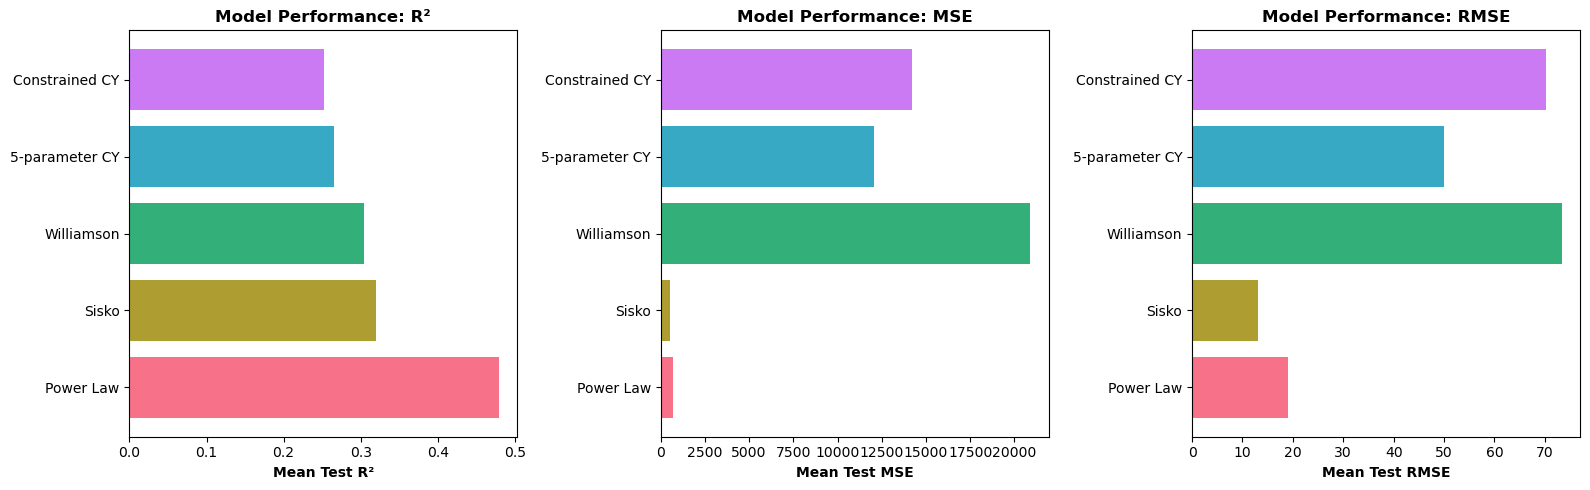

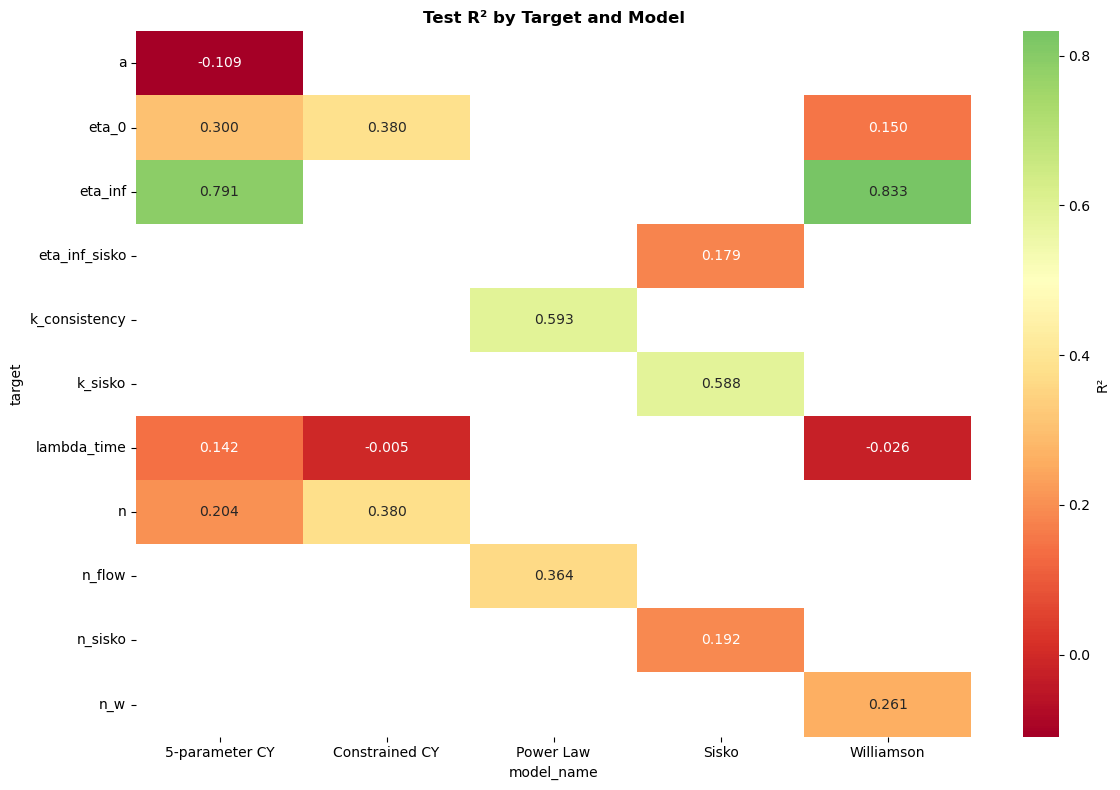

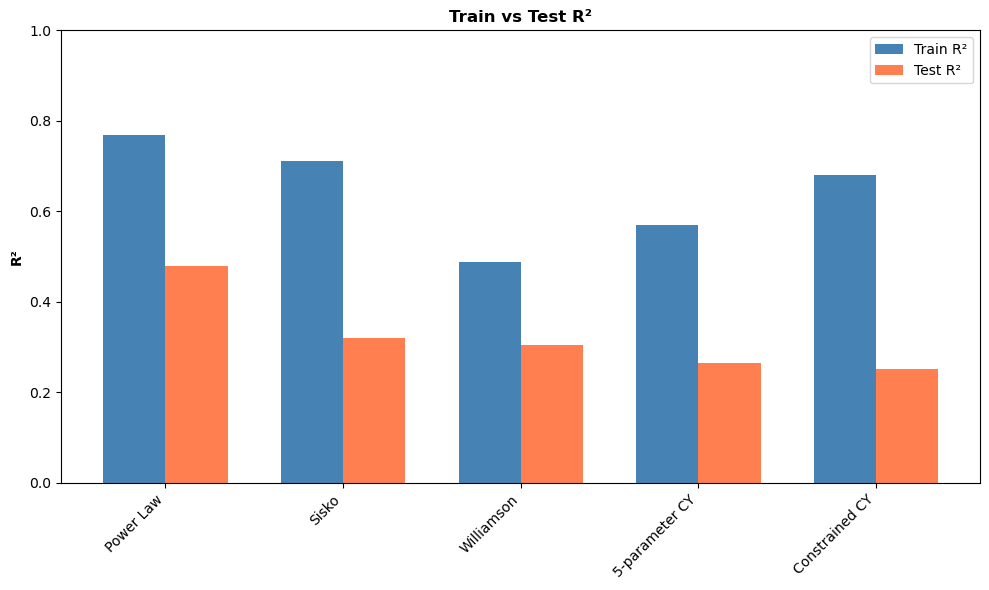

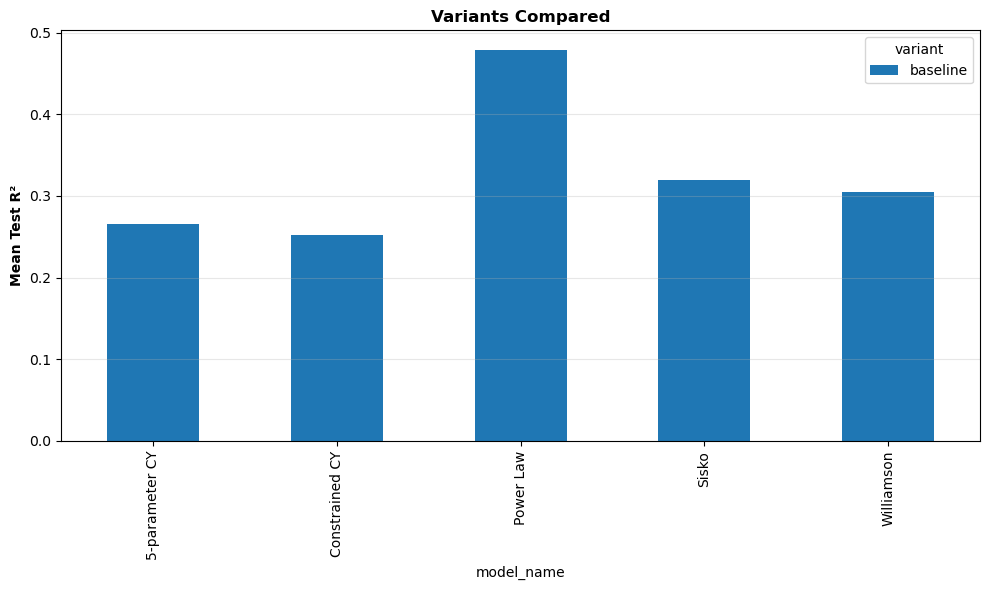

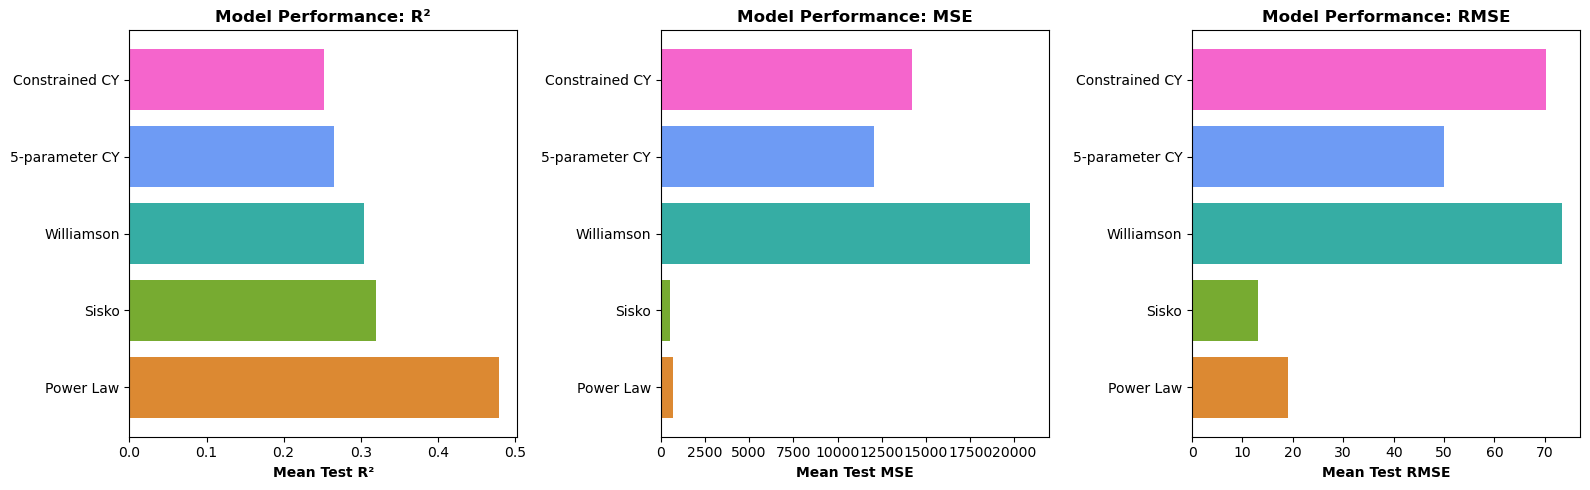

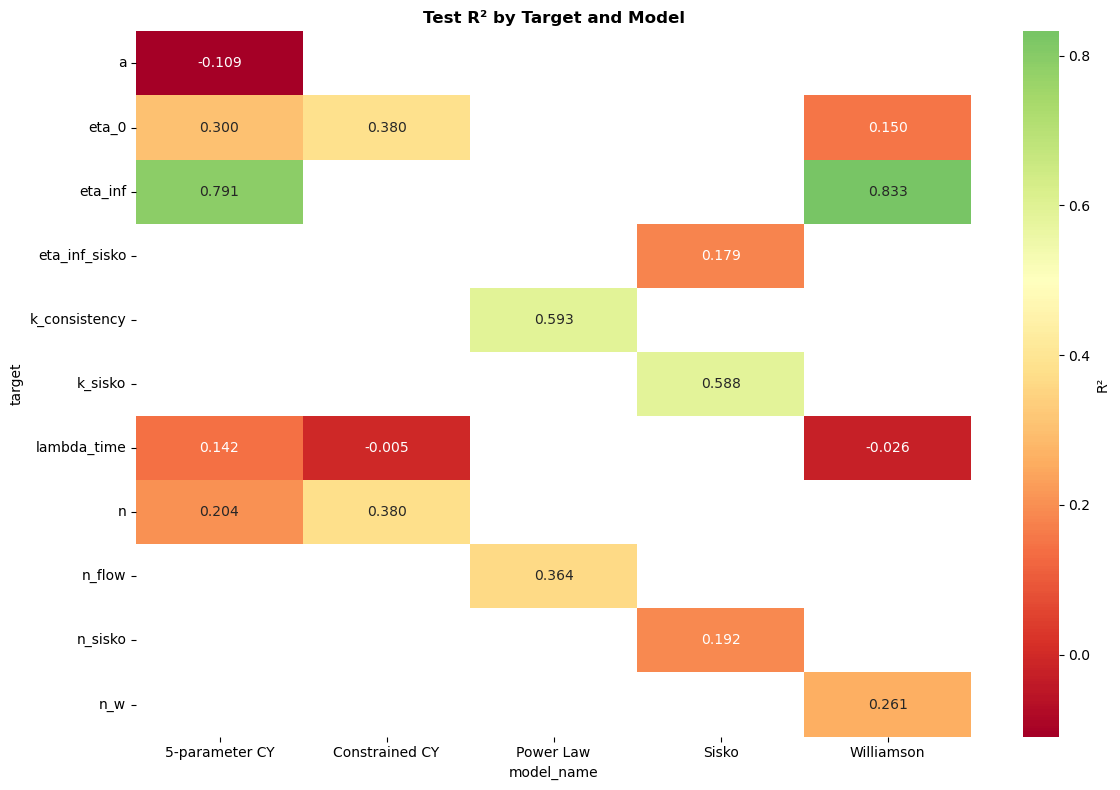

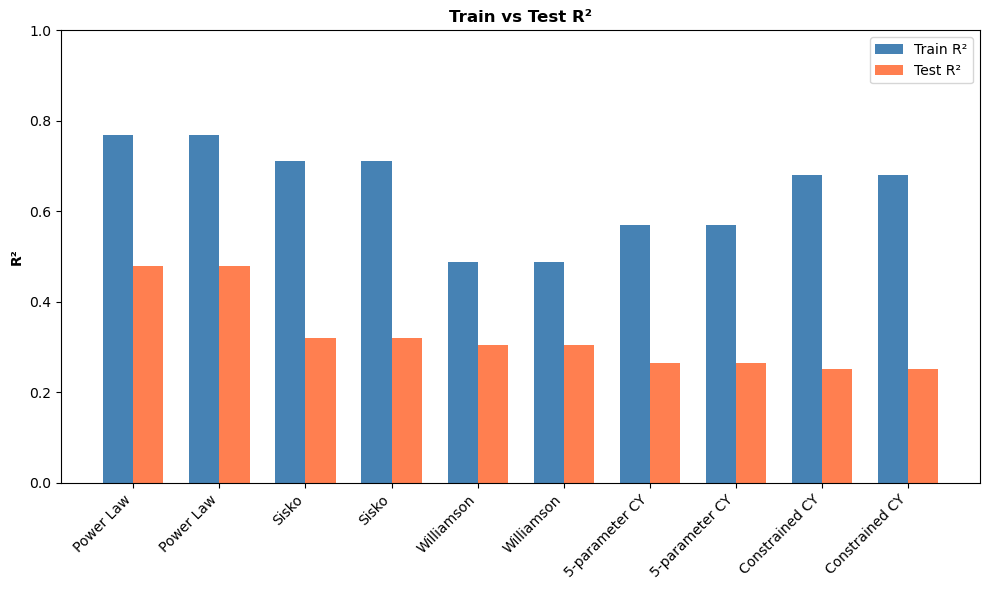

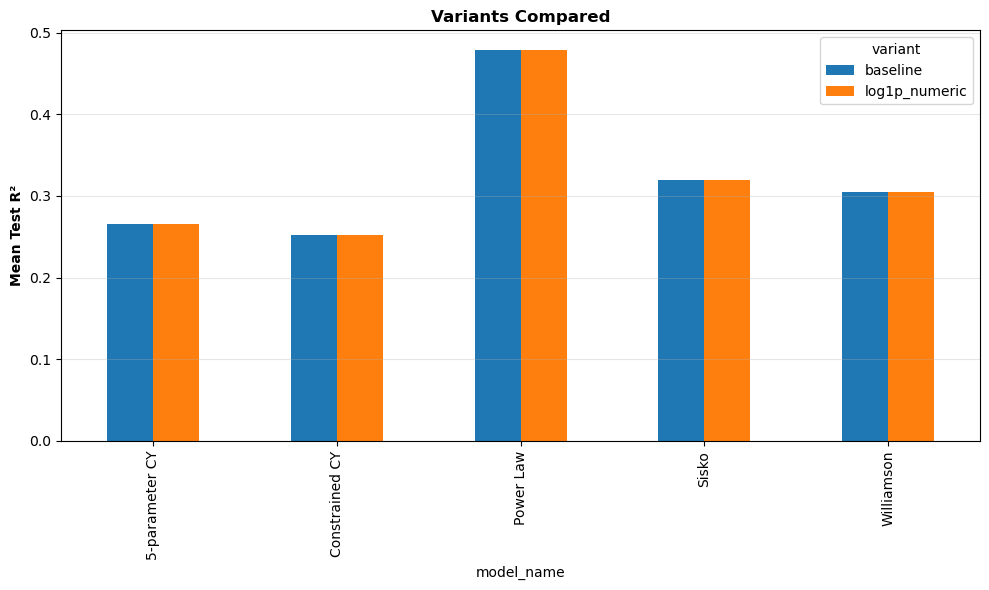

In [20]:
saved = make_all_plots(results, cfg.results_dir)
for p in saved:
    print(p)

## Compare completed experiments

The `experiment_manifest.json` at the top of `data/processed/xgboost_experiments/` accumulates every run across the project.

In [21]:
import json
import pandas as pd

manifest_path = cfg.experiments_root_path / 'experiment_manifest.json'
if manifest_path.exists():
    runs = json.loads(manifest_path.read_text())['runs']
    df = pd.json_normalize(runs)
    display(df[['experiment_id', 'description', 'sections_run', 'best.model_name', 'best.test_r2', 'created_at_utc']])
else:
    print('No manifest yet. Run an experiment first.')

,experiment_id,description,sections_run,best.model_name,best.test_r2,created_at_utc
0,exp_004_trials_20_raw,Higher trials + raw features.,"[baseline, sweep]",Power Law,0.478763,2026-04-20T12:14:23.672889+00:00
1,exp_003_raw_only,Raw features only (no engineered features).,"[baseline, sweep]",Power Law,0.491317,2026-04-20T11:58:15.820653+00:00
2,exp_002_trials_20,Higher trial budget: 20 Optuna trials.,"[baseline, sweep]",Power Law,0.433388,2026-04-20T11:48:42.831230+00:00
3,exp_001_baseline,"Baseline: engineered features, 10 trials.","[baseline, sweep]",Power Law,0.461717,2026-04-20T11:27:35.152265+00:00
